# Evolución del precio de la tortilla en México (2007-2026)

**Visualización de datos, Maestría en Inteligencia Artificial, ITA**
Avance 3 del proyecto. Autora: Yomira del Carmen Rosales Martínez

**Pregunta analítica.** ¿Cómo ha evolucionado entre 2007 y 2026 el precio de la tortilla por entidad federativa y canal de venta (tortillerías y autoservicio)?

**Contenido del notebook**
1. Entorno y configuración
2. Carga de datos
3. Limpieza (con bitácora)
4. Datos procesados para otras herramientas (Tableau)
5. Exploración de datos (EDA)
6. Visualización estática
7. Visualización interactiva
8. Componente de Business Intelligence
9. Conclusiones

## 1. Entorno y configuración
Las rutas son **relativas** a la raíz del repositorio. Si se ejecuta el notebook desde la carpeta `notebooks/`, la primera línea del siguiente bloque cambia el directorio de trabajo.

In [1]:
import os, platform
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RUTA_DATOS = Path("data/tortilla_prices.csv")
CARPETA_PROC = Path("data/processed")
CARPETA_FIG = Path("figuras")
YEAR_REF = 2025
CARPETA_PROC.mkdir(parents=True, exist_ok=True)
CARPETA_FIG.mkdir(exist_ok=True)

COLORES = {"Tortillerías": "#D55E00", "Autoservicio": "#0072B2"}
FUENTE = "Fuente: SNIIM, Secretaría de Economía (vía Kaggle, R. Chavelas). Precios nominales."

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.14.7 | pandas 3.0.0 | matplotlib 3.10.8 | seaborn 0.13.2


## 2. Carga de datos
- **Dataset:** *Tortilla Prices in Mexico*, Rick Chavelas (Kaggle). https://www.kaggle.com/datasets/richave/tortilla-prices-in-mexico
- **Fuente primaria:** SNIIM, Secretaría de Economía. http://www.economia-sniim.gob.mx/Tortilla.asp
- **Licencia:** CC0
- **Fecha de descarga:** 3 de Octubre de 2026
- El archivo es una copia derivada: el autor extrajo los datos del SNIIM mediante *web scraping* y los limpió sin documentar los pasos. Cada registro es el precio promedio por kilogramo (MXN, nominales) de un día, ciudad y canal.

In [2]:
if not RUTA_DATOS.exists():
    raise FileNotFoundError(
        "No se encontró data/tortilla_prices.csv. Descárgalo de Kaggle "
        "y guárdalo en la carpeta data/.")

crudo = pd.read_csv(RUTA_DATOS)
print("Filas y columnas:", crudo.shape)
print("Rango de fechas:", pd.to_datetime(dict(year=crudo.Year, month=crudo.Month, day=crudo.Day)).agg(["min", "max"]).dt.date.tolist())
crudo.head()

Filas y columnas: (313230, 7)
Rango de fechas: [datetime.date(2007, 1, 10), datetime.date(2026, 4, 17)]


,State,City,Year,Month,Day,Store type,Price per kilogram
0,Aguascalientes,Aguascalientes,2007,1,10,Mom and Pop Store,9.9
1,Baja California,Mexicali,2007,1,10,Mom and Pop Store,NaN
2,Baja California,Tijuana,2007,1,10,Mom and Pop Store,10.0
3,Baja California Sur,La Paz,2007,1,10,Mom and Pop Store,10.0
4,Campeche,Campeche,2007,1,10,Mom and Pop Store,10.0


## 3. Limpieza de datos
Decisiones tomadas (cada una queda registrada en la bitácora):
1. Eliminar espacios no separables (`\xa0`) en `State` y `City`.
2. Homologar nombres de entidades: "D.F." → "Ciudad de México" y "Edo. México" → "Estado de México".
3. Renombrar los canales con las etiquetas del SNIIM: *Mom and Pop Store* → **Tortillerías**; *Big Retail Store* → **Autoservicio**.
4. Construir una variable de fecha a partir de `Year`, `Month` y `Day`.
5. **No se imputan valores.** Los precios faltantes y el precio ≤ 0 se excluyen del cálculo.

In [3]:
df = crudo.copy()
bitacora = [("Registros originales", len(df))]

n_nbsp = int(df["State"].str.contains("\xa0").sum() + df["City"].str.contains("\xa0").sum())
df["State"] = df["State"].str.replace("\xa0", " ", regex=False).str.strip()
df["City"] = df["City"].str.replace("\xa0", " ", regex=False).str.strip()
bitacora.append(("Celdas con espacios no separables corregidas", n_nbsp))

cambios = {"D.F.": "Ciudad de México", "Edo. México": "Estado de México"}
bitacora.append(("Registros con nombre de entidad homologado", int(df["State"].isin(cambios).sum())))
df["State"] = df["State"].replace(cambios)

df["Canal"] = df["Store type"].map({"Mom and Pop Store": "Tortillerías",
                                    "Big Retail Store": "Autoservicio"})
assert df["Canal"].notna().all()

df["Fecha"] = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=df["Day"]))

df["Precio"] = df["Price per kilogram"]
bitacora.append(("Precios faltantes (excluidos)", int(df["Precio"].isna().sum())))
bitacora.append(("Precios menores o iguales a 0 (excluidos)", int((df["Precio"] <= 0).sum())))

d = df[df["Precio"] > 0].copy()
bitacora.append(("Registros válidos para el análisis", len(d)))

assert d["State"].nunique() == 32
pd.DataFrame(bitacora, columns=["Paso", "Registros"])

,Paso,Registros
0,Registros originales,313230
1,Celdas con espacios no separables corregidas,132243
2,Registros con nombre de entidad homologado,17442
3,Precios faltantes (excluidos),6574
4,Precios menores o iguales a 0 (excluidos),1
5,Registros válidos para el análisis,306655


In [4]:
# Dónde se concentran los faltantes
faltantes_por_year = df[df["Precio"].isna()].groupby("Year").size().rename("Precios faltantes")
faltantes_por_year.to_frame().T

Year,2007,2008,2012,2013,2014,2016,2018,2019,2020,2021,2022,2023,2024,2025,2026
Precios faltantes,253,82,328,664,198,487,4,786,3000,440,4,142,2,82,102


## 4. Datos procesados para otras herramientas
Se exporta una tabla **mensual por entidad y canal** que usarán la gráfica interactiva y Tableau. Guarda `Suma_precio` y `N_obs` (no solo el promedio) para que el promedio ponderado de cualquier selección coincida con el de este notebook: `SUM(Suma_precio) / SUM(N_obs)`.

In [5]:
mensual = (d.assign(Fecha_mes=d["Fecha"].dt.to_period("M").dt.to_timestamp())
             .groupby(["Fecha_mes", "State", "Canal"])
             .agg(Suma_precio=("Precio", "sum"),
                  N_obs=("Precio", "size"),
                  Ciudades=("City", "nunique"))
             .reset_index()
             .rename(columns={"Fecha_mes": "Fecha"}))
mensual["Year"] = mensual["Fecha"].dt.year
mensual["Month"] = mensual["Fecha"].dt.month
mensual["Precio_promedio"] = (mensual["Suma_precio"] / mensual["N_obs"]).round(4)
mensual = mensual[["Fecha", "Year", "Month", "State", "Canal",
                   "Suma_precio", "N_obs", "Ciudades", "Precio_promedio"]]

mensual.to_csv(CARPETA_PROC / "tortilla_mensual.csv", index=False, encoding="utf-8-sig")
print(mensual.shape)
mensual.head()

(14742, 9)


,Fecha,Year,Month,State,Canal,Suma_precio,N_obs,Ciudades,Precio_promedio
0,2007-01-01,2007,1,Aguascalientes,Autoservicio,98.72,17,1,5.8071
1,2007-01-01,2007,1,Aguascalientes,Tortillerías,167.70,17,1,9.8647
2,2007-01-01,2007,1,Baja California,Autoservicio,137.37,23,2,5.9726
3,2007-01-01,2007,1,Baja California,Tortillerías,244.03,23,2,10.6100
4,2007-01-01,2007,1,Baja California Sur,Autoservicio,95.06,17,1,5.5918


In [6]:
anual = mensual.groupby(["Year", "Canal"])[["Suma_precio", "N_obs"]].sum()
anual["Precio_promedio"] = anual["Suma_precio"] / anual["N_obs"]
p = anual["Precio_promedio"].unstack()

print(p.loc[[2007, 2019, 2025]].round(2))
print("Crecimiento 2019-2025 (%):", ((p.loc[2025] / p.loc[2019] - 1) * 100).round(1).to_dict())
print("Brecha entre canales ($/kg):", (p["Tortillerías"] - p["Autoservicio"]).loc[[2007, 2019, 2025]].round(2).to_dict())

Canal  Autoservicio  Tortillerías
Year                             
2007           5.74          8.97
2019          11.08         15.76
2025          14.50         25.23
Crecimiento 2019-2025 (%): {'Autoservicio': 30.9, 'Tortillerías': 60.1}
Brecha entre canales ($/kg): {2007: 3.22, 2019: 4.68, 2025: 10.72}


In [7]:
# Salario mínimo general diario (pesos). Compáralo con tu tabla de CONASAMI.
sm = pd.DataFrame({
    "Year": list(range(2007, 2027)),
    "Salario": [50.57, 52.59, 54.80, 57.46, 59.82, 62.33, 64.76, 67.29, 70.10, 73.04,
                80.04, 88.36, 102.68, 123.22, 141.70, 172.87, 207.44, 248.93,
                278.80,    # 2025 verificado
                315.04],   # 2026 verificado (año parcial: ene-abr)
})

precio_anual = (d.groupby(["Year", "Canal"], as_index=False)["Precio"].mean()
                  .merge(sm, on="Year", how="left"))
assert precio_anual["Salario"].notna().all()

precio_anual["Minutos"] = precio_anual["Precio"] / precio_anual["Salario"] * 480
precio_anual["Kg_por_jornada"] = precio_anual["Salario"] / precio_anual["Precio"]

minutos = precio_anual.pivot(index="Year", columns="Canal", values="Minutos")
print(minutos.loc[[2007, 2019, 2025]].round(1))
print("Cambio 2007-2025 (%):", ((minutos.loc[2025] / minutos.loc[2007] - 1) * 100).round(1).to_dict())
print(precio_anual.pivot(index="Year", columns="Canal", values="Kg_por_jornada").loc[[2007, 2019, 2025]].round(1))

Canal  Autoservicio  Tortillerías
Year                             
2007           54.5          85.1
2019           51.8          73.7
2025           25.0          43.4
Cambio 2007-2025 (%): {'Autoservicio': -54.2, 'Tortillerías': -49.0}
Canal  Autoservicio  Tortillerías
Year                             
2007            8.8           5.6
2019            9.3           6.5
2025           19.2          11.1


## 5. Exploración de datos (EDA)
Las cinco visualizaciones del Avance 2. Las figuras se guardan en `figuras/`.

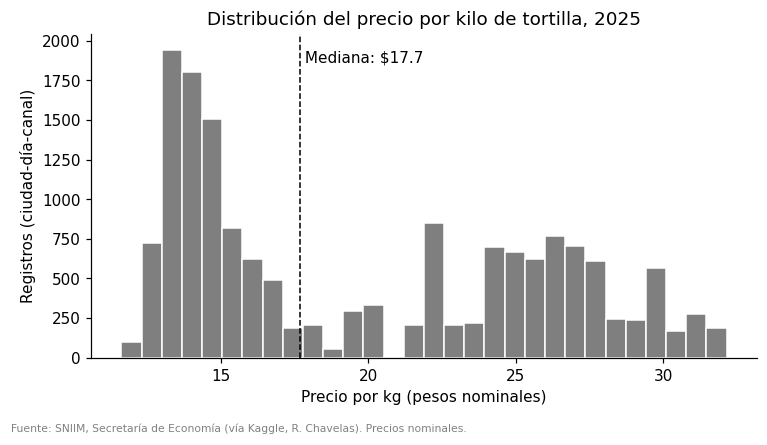

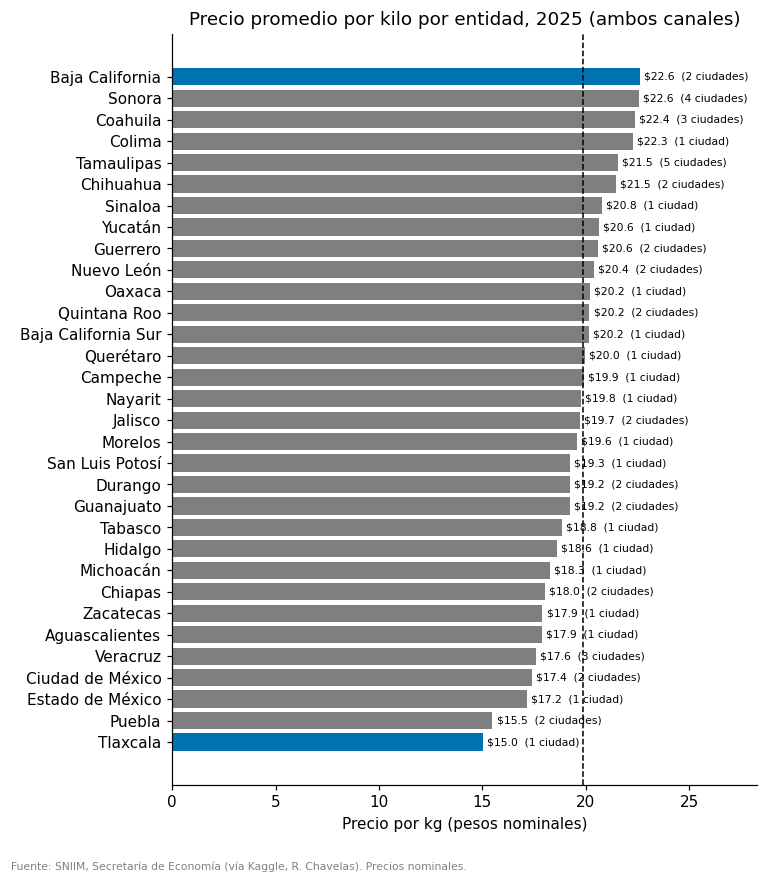

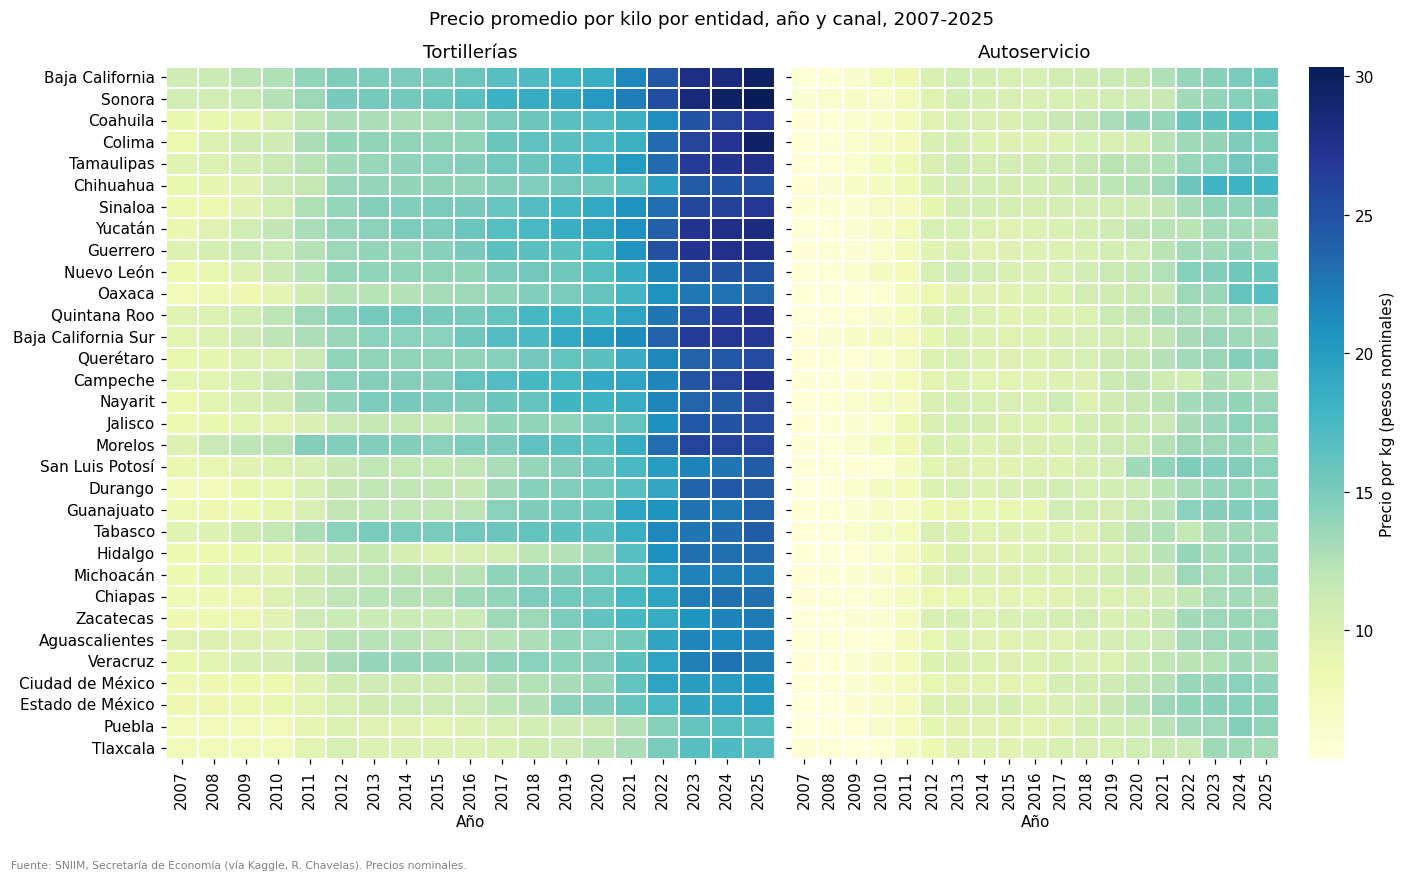

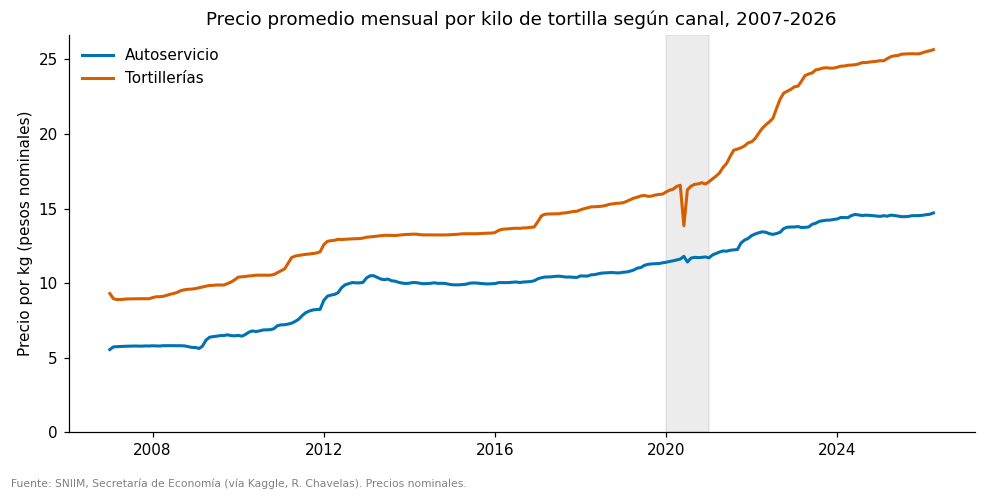

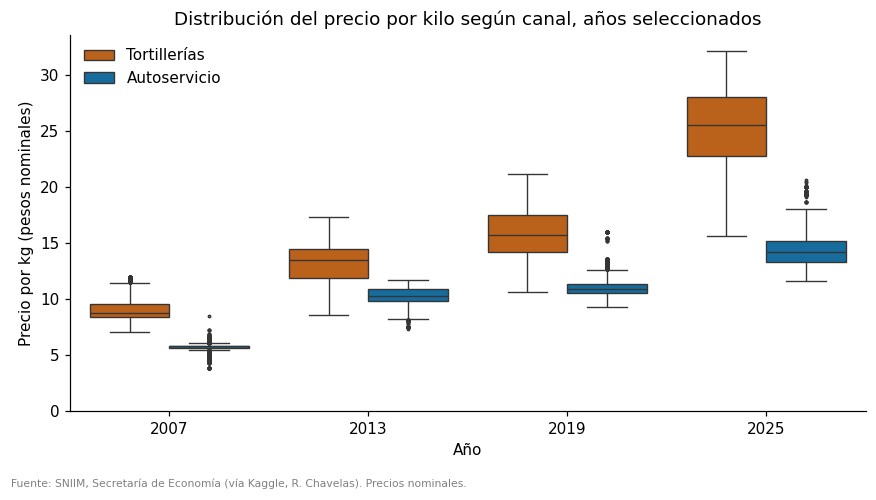

In [8]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
d25 = d[d["Year"] == YEAR_REF]

def guardar(fig, nombre):
    fig.text(0.01, 0.005, FUENTE, fontsize=7, color="gray")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(CARPETA_FIG / nombre, dpi=150)
    plt.show()
    plt.close(fig)

def fig1_histograma():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(d25["Precio"], bins=30, color="#7f7f7f", edgecolor="white")
    mediana = d25["Precio"].median()
    ax.axvline(mediana, color="black", ls="--", lw=1)
    ax.text(mediana, ax.get_ylim()[1] * 0.95, f" Mediana: ${mediana:.1f}", va="top")
    ax.set_title(f"Distribución del precio por kilo de tortilla, {YEAR_REF}")
    ax.set_xlabel("Precio por kg (pesos nominales)")
    ax.set_ylabel("Registros (ciudad-día-canal)")
    guardar(fig, f"fig1_histograma_{YEAR_REF}.png")

def fig2_barras_entidad():
    est = d25.groupby("State")["Precio"].mean().sort_values()
    n_ciudades = d25.groupby("State")["City"].nunique()
    colores = ["#7f7f7f"] * len(est)
    colores[0] = colores[-1] = "#0072B2"
    fig, ax = plt.subplots(figsize=(7, 8))
    ax.barh(est.index, est.values, color=colores)
    ax.axvline(d25["Precio"].mean(), color="black", ls="--", lw=1)
    for i, (estado, v) in enumerate(est.items()):
        n = n_ciudades[estado]
        ax.text(v + 0.2, i, f"${v:.1f}  ({n} ciudad{'es' if n > 1 else ''})", va="center", fontsize=7)
    ax.set_xlim(0, est.max() * 1.25)
    ax.set_title(f"Precio promedio por kilo por entidad, {YEAR_REF} (ambos canales)")
    ax.set_xlabel("Precio por kg (pesos nominales)")
    guardar(fig, f"fig2_barras_entidad_{YEAR_REF}.png")

def fig3_mapa_calor():
    h = d[d["Year"] <= YEAR_REF].groupby(["State", "Year", "Canal"])["Precio"].mean().reset_index()
    orden = h[h["Year"] == YEAR_REF].groupby("State")["Precio"].mean().sort_values(ascending=False).index
    fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
    for ax, canal in zip(axes, ["Tortillerías", "Autoservicio"]):
        m = h[h["Canal"] == canal].pivot(index="State", columns="Year", values="Precio").reindex(orden)
        sns.heatmap(m, ax=ax, cmap="YlGnBu", vmin=h["Precio"].min(), vmax=h["Precio"].max(),
                    cbar=(canal == "Autoservicio"),
                    cbar_kws={"label": "Precio por kg (pesos nominales)"},
                    linewidths=0.3, linecolor="white")
        ax.set_title(canal); ax.set_xlabel("Año"); ax.set_ylabel("")
    fig.suptitle(f"Precio promedio por kilo por entidad, año y canal, 2007-{YEAR_REF}")
    guardar(fig, "fig3_mapa_calor.png")

def fig4_serie_tiempo():
    t = d.set_index("Fecha").groupby("Canal")["Precio"].resample("MS").mean().reset_index()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for canal, g in t.groupby("Canal"):
        ax.plot(g["Fecha"], g["Precio"], color=COLORES[canal], lw=2, label=canal)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.15)
    ax.set_ylim(0, None)
    ax.set_title("Precio promedio mensual por kilo de tortilla según canal, 2007-2026")
    ax.set_ylabel("Precio por kg (pesos nominales)")
    ax.legend(frameon=False)
    guardar(fig, "fig4_serie_tiempo.png")

def fig5_boxplot():
    b = d[d["Year"].isin([2007, 2013, 2019, 2025])]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.boxplot(data=b, x="Year", y="Precio", hue="Canal", hue_order=list(COLORES),
                palette=COLORES, fliersize=1.5, linewidth=0.9, ax=ax)
    ax.set_ylim(0, None)
    ax.set_title("Distribución del precio por kilo según canal, años seleccionados")
    ax.set_xlabel("Año"); ax.set_ylabel("Precio por kg (pesos nominales)")
    ax.legend(title="", frameon=False)
    guardar(fig, "fig5_boxplot.png")

for fig in (fig1_histograma, fig2_barras_entidad, fig3_mapa_calor, fig4_serie_tiempo, fig5_boxplot):
    fig()

## 6. Visualización estática final
Versión mejorada de la serie de tiempo del Avance 2 (figura 4). Cambios respecto a la versión anterior:
- Título que comunica el hallazgo, con subtítulo que indica medida y periodo.
- Etiquetado directo al final de cada línea.
- Área sombreada y flechas que destacan la brecha entre canales.
- Los meses con cobertura insuficiente **no se grafican**
- 2026 marcado como año parcial, y nota de fuente y de precios nominales.

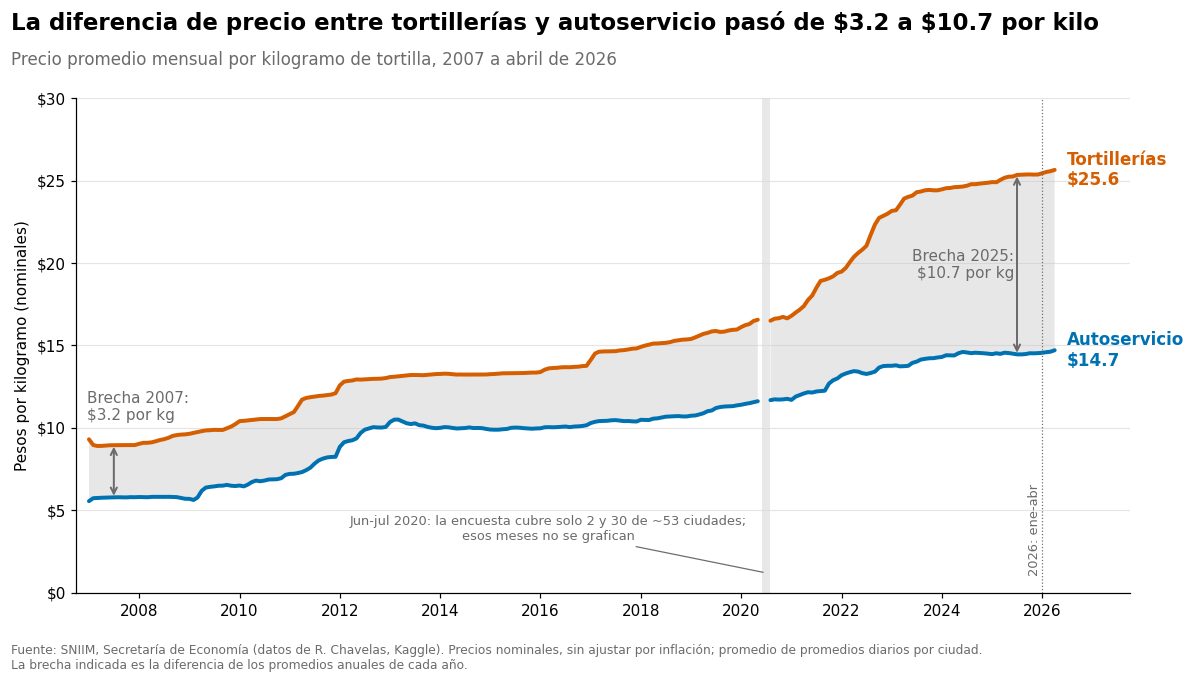

Meses omitidos: ['2020-06', '2020-07']
Brecha anual 2007 y 2025: 3.22 10.72


In [9]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

UMBRAL_CIUDADES = 45

serie = (d.set_index("Fecha").groupby("Canal")["Precio"].resample("MS").mean().unstack(0))
ciudades = (d.assign(Mes=d["Fecha"].dt.to_period("M").dt.to_timestamp())
              .groupby(["Mes", "Canal"])["City"].nunique().unstack())
meses_omitidos = ciudades.index[(ciudades < UMBRAL_CIUDADES).any(axis=1)]
serie_plot = serie.copy()
serie_plot.loc[meses_omitidos] = np.nan

anual = d.groupby(["Year", "Canal"])["Precio"].mean().unstack()
brecha = anual["Tortillerías"] - anual["Autoservicio"]
b07, b25 = brecha[2007], brecha[2025]

NARANJA, AZUL, GRIS = COLORES["Tortillerías"], COLORES["Autoservicio"], "#6b6b6b"

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.fill_between(serie_plot.index, serie_plot["Autoservicio"], serie_plot["Tortillerías"],
                color="#bdbdbd", alpha=0.35, linewidth=0, label="_nolegend_")
ax.plot(serie_plot.index, serie_plot["Tortillerías"], color=NARANJA, lw=2.6, solid_capstyle="round")
ax.plot(serie_plot.index, serie_plot["Autoservicio"], color=AZUL, lw=2.6, solid_capstyle="round")

ult = serie.index.max()
for canal, color in (("Tortillerías", NARANJA), ("Autoservicio", AZUL)):
    ax.annotate(f"{canal}\n\\${serie.loc[ult, canal]:.1f}", xy=(ult, serie.loc[ult, canal]),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=color, fontsize=11, fontweight="bold")

def anota_brecha(anio, valor, dx_texto):
    f = pd.Timestamp(f"{anio}-07-01")
    y0, y1 = serie.loc[f, "Autoservicio"], serie.loc[f, "Tortillerías"]
    ax.annotate("", xy=(f, y1), xytext=(f, y0),
                arrowprops=dict(arrowstyle="<->", color=GRIS, lw=1.3, shrinkA=1, shrinkB=1))
    ax.text(f + pd.Timedelta(days=dx_texto), (y0 + y1) / 2, f"Brecha {anio}:\n\\${valor:.1f} por kg",
            color=GRIS, fontsize=10, va="center")

anota_brecha(2007, b07, 95)
ax.texts[-1].set_position((pd.Timestamp("2006-12-15"), 10.3))
ax.texts[-1].set_va("bottom")
anota_brecha(2025, b25, -20)
ax.texts[-1].set_ha("right")

ax.axvspan(pd.Timestamp("2020-06-01"), pd.Timestamp("2020-08-01"), color="#d9d9d9", alpha=0.6, lw=0)
ax.annotate("Jun-jul 2020: la encuesta cubre solo 2 y 30 de ~53 ciudades;\nesos meses no se grafican",
            xy=(pd.Timestamp("2020-07-01"), 1.2), xytext=(pd.Timestamp("2016-03-01"), 3.2),
            fontsize=8.5, color=GRIS, ha="center",
            arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
ax.axvline(pd.Timestamp("2026-01-01"), color=GRIS, lw=0.8, ls=":")
ax.text(pd.Timestamp("2025-12-20"), 1.0, "2026: ene-abr", rotation=90,
        ha="right", va="bottom", fontsize=8.5, color=GRIS)

ax.set_ylim(0, 30)
ax.set_xlim(pd.Timestamp("2006-10-01"), pd.Timestamp("2027-10-01"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.0f}"))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
ax.set_ylabel("Pesos por kilogramo (nominales)")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.975, f"La diferencia de precio entre tortillerías y autoservicio pasó de \\${b07:.1f} a \\${b25:.1f} por kilo",
         ha="left", va="top", fontsize=15, fontweight="bold")
fig.text(0.01, 0.917, "Precio promedio mensual por kilogramo de tortilla, 2007 a abril de 2026",
         ha="left", va="top", fontsize=11, color=GRIS)
fig.text(0.01, 0.01,
         "Fuente: SNIIM, Secretaría de Economía (datos de R. Chavelas, Kaggle). Precios nominales, sin ajustar por inflación; "
         "promedio de promedios diarios por ciudad.\n"
         "La brecha indicada es la diferencia de los promedios anuales de cada año.",
         ha="left", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.06, 1, 0.88))
fig.savefig(CARPETA_FIG / "fig_estatica_serie_tiempo.png", dpi=200)
plt.show()

print("Meses omitidos:", [m.strftime("%Y-%m") for m in meses_omitidos])
print("Brecha anual 2007 y 2025:", round(b07, 2), round(b25, 2))

## 7. Visualización interactiva: precio por entidad, año y canal

Gráfica de barras horizontales con tres controles: canal de venta, año y
reproducción automática 2007–2026. Al pasar el cursor sobre una barra se ve el precio, el número
de ciudades y el número de registros que lo respaldan. Las barras se reordenan en cada vista.
Se guarda como `html/precio_por_entidad.html`.

## 8. Componente de Business Intelligence


**Enlace público del dashboard:** [https://public.tableau.com/views/DashboardPreciodelatortillade2007a2026/Dashboard1?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link]

**Datos de entrada:** `data/processed/tortilla_mensual.csv`, exportada en la sección 2 de este
notebook (una fila por mes, entidad y canal).

**Contenido del dashboard:** tres indicadores (precio promedio en tortillerías, en autoservicio y
brecha), un mapa por entidad, la serie mensual por canal y filtros de año y canal.

**Campo calculado clave:** el precio promedio se calcula como `SUM([Suma_precio]) / SUM([N_obs])`,
no como promedio de la columna `Precio_promedio`.

**Limitaciones:** el mapa colorea estados completos aunque 17 de 32 entidades tienen una sola
ciudad; junio y julio de 2020 tienen cobertura muy baja; 2026 solo incluye enero a abril; los precios son nominales.

## 9. Conclusiones

- **La brecha entre canales creció.** En 2007 el kilo costaba en promedio $3.22 más en tortillerías
  que en autoservicio; en 2025, $10.72. Entre 2019 y 2025 el precio aumentó 60.1% en tortillerías
  y 30.9% en autoservicio.
- **El precio varía entre entidades.** En 2025 los promedios más bajos fueron los de Tlaxcala
  ($15.05) y Puebla ($15.48) y los más altos los de Baja California ($22.61), Sonora ($22.57) y
  Coahuila ($22.37). Muchas entidades están representadas por una sola ciudad, por lo que estos
  promedios deben leerse con cautela.
- **Cada herramienta aporta algo distinto.** La gráfica estática comunica un hallazgo único; la
  interactiva permite explorar combinaciones de año y canal; el dashboard permite monitorear
  indicadores y geografía en una sola vista.
- **Limitaciones.** Precios nominales, cobertura irregular en 2020, 2026 parcial (enero a abril) y promedios de promedios.